# Nested Benders decomposition, step by step

The nested L-shaped method (Birge, 1985), or nested Benders decomposition, solves a multistage
stochastic linear program on a scenario tree by applying the L-shaped method recursively: every
node of the tree is at once the **master problem** of its children and a **subproblem** of its
parent. This notebook writes the method from scratch, following the slides *06. Multistage
problems* (nested decomposition, cuts, forward and backward passes). The aim is to expose the
principle, not to be efficient:

- **one JuMP model per node**: the problem of a node is an ordinary JuMP model, written by the user;
  the algorithm only adds a copy of the parent's decision, the variable $\theta$ and the cuts;
- **every node is solved at every iteration**: no sampling, no cut selection, no clever sequencing;
- **the bounds are exact**: the forward pass evaluates its policy on the whole tree.

The same code is in `nested_benders.jl`, which can be `include`d, or run as a script. The notebook
*SDDP_from_scratch* takes the next step: under stagewise independence, the nodes of a stage share
their cuts, and the forward pass samples scenarios instead of enumerating the tree.

In [1]:
using JuMP
using HiGHS
using Printf
using Plots

## 1. The problem

Over the stages $t = 1, \ldots, H$, we solve
$$
\min_{x_1 \geq 0}\ c_1^T x_1 + \mathbb{E}\Bigl[ \min_{x_2 \geq 0} c_2^T x_2
  + \mathbb{E}\bigl[ \cdots + \mathbb{E}[ \min_{x_H \geq 0} c_H^T x_H ] \bigr] \Bigr]
$$
subject to $W_1 x_1 = h_1$ and $W_t x_t = h_t(\xi_t) - T_{t-1}(\xi_t) x_{t-1}$, $t = 2, \ldots, H$.
On a scenario tree, stage $t$ has one node $k$ per history $\xi_{[t]}$, and the dynamic programming
recursion reads, with $\mathcal{Q}_{H+1} \equiv 0$,
$$
\begin{aligned}
V_t(x_{t-1}, \xi_{[t]}) &= \min_{x_t \geq 0} \left\{ c_t^T x_t + \mathcal{Q}_{t+1}(x_t, \xi_{[t]}) \ :\
  W_t x_t = h_t(\xi_t) - T_{t-1}(\xi_t) x_{t-1} \right\}, \\
\mathcal{Q}_{t+1}(x_t, \xi_{[t]}) &= \mathbb{E}\left[ V_{t+1}(x_t, \xi_{[t+1]}) \mid \xi_{[t]} \right].
\end{aligned}
$$
Nested decomposition approximates each expected cost-to-go $\mathcal{Q}_{t+1}(\cdot, \xi_{[t]})$,
one function per node, from below, by cuts on a variable $\theta_{t,k}$.

## 2. The scenario tree

A node stores its stage $t$, its parent $a(k)$, the conditional probability
$p(k, t \mid a(k), t-1)$ of the branch from its parent, and the data $\xi_t$ observed when it is
reached. Nodes are numbered as they are added, so that a parent always comes before its children.

In [2]:
"""
    Node(stage, parent, probability, data)

A node of the scenario tree: its stage `t`, its parent `a(k)` (`0` at the root), the conditional
probability `p(k, t | a(k), t-1)` of the branch from its parent, and the data `ξ_t` observed when the
node is reached, in whatever form the model builder expects.
"""
struct Node
    stage::Int
    parent::Int
    probability::Float64
    data::Any
end

"""
    ScenarioTree(root_data = nothing)

A tree reduced to its root, node 1. Nodes are added with [`add_node!`](@ref) and numbered in that
order, so that a parent always comes before its children.
"""
struct ScenarioTree
    nodes::Vector{Node}
    children::Vector{Vector{Int}}
end

ScenarioTree(root_data = nothing) = ScenarioTree([Node(1, 0, 1.0, root_data)], [Int[]])

"""
    add_node!(tree, parent, probability, data) -> k

Add a child to node `parent`, reached with the conditional probability `probability`, where `data`
is observed. Return its index `k`.
"""
function add_node!(tree::ScenarioTree, parent::Int, probability::Real, data)
    push!(tree.nodes, Node(tree.nodes[parent].stage + 1, parent, probability, data))
    push!(tree.children, Int[])
    k = length(tree.nodes)
    push!(tree.children[parent], k)
    return k
end

nstages(tree::ScenarioTree) = maximum(node.stage for node in tree.nodes)
stage_nodes(tree::ScenarioTree, t) = [k for (k, node) in enumerate(tree.nodes) if node.stage == t]
isleaf(tree::ScenarioTree, k) = isempty(tree.children[k])

"""Unconditional probability of node `k`: the product of the branch probabilities from the root."""
function node_probability(tree::ScenarioTree, k)
    p = 1.0
    while k != 0
        p *= tree.nodes[k].probability
        k = tree.nodes[k].parent
    end
    return p
end

"""
    stagewise_tree(outcomes, probabilities; root_data = nothing)

The full tree in which every node of stage `t` has one child per element of `outcomes[t]`, reached
with the probabilities `probabilities[t]`: stagewise independent data, `length(outcomes) + 1` stages.
Any other tree is built with [`add_node!`](@ref).
"""
function stagewise_tree(outcomes, probabilities; root_data = nothing)
    tree = ScenarioTree(root_data)
    frontier = [1]
    for (ξs, ps) in zip(outcomes, probabilities)
        frontier = [add_node!(tree, k, p, ξ) for k in frontier for (ξ, p) in zip(ξs, ps)]
    end
    return tree
end

"""Check that the branch probabilities out of every node sum up to one."""
function check_tree(tree::ScenarioTree)
    for (j, K) in enumerate(tree.children)
        isempty(K) && continue
        total = sum(tree.nodes[k].probability for k in K)
        isapprox(total, 1; atol = 1e-9) ||
            error("the branch probabilities out of node $j sum up to $total, not 1")
    end
end

check_tree

Our example is the financial planning problem of the slides (Birge and Louveaux, Section 1.2): two
assets, stocks and bonds, $H = 3$ investment periods, and each period the returns are
$(1.25, 1.14)$ or $(1.06, 1.12)$, with probability $1/2$. A node of stage $t \geq 2$ observes the
returns of period $t - 1$; the surplus and the shortfall are decided at stage $H + 1 = 4$, whose eight
nodes are the scenarios.

In [3]:
"""The tree of the example: each period, the returns of (stocks, bonds) are (1.25, 1.14) or (1.06, 1.12),
with probability 1/2, independently of the past."""
financial_tree(H = 3) = stagewise_tree(fill([[1.25, 1.14], [1.06, 1.12]], H), fill([0.5, 0.5], H))

financial_tree

In [4]:
tree = financial_tree(3)
@printf("%4s %5s %6s %6s %8s   %s\n", "node", "stage", "parent", "p", "P(node)", "returns observed")
for (k, node) in enumerate(tree.nodes)
    @printf("%4d %5d %6d %6.2f %8.4f   %s\n", k, node.stage, node.parent, node.probability,
            node_probability(tree, k), node.data === nothing ? "-" : string(node.data))
end

node stage parent      p  P(node)   returns observed
   1     1      0   1.00   1.0000   -


   2     2      1   0.50   0.5000   [1.25, 1.14]
   3     2      1   0.50   0.5000   [1.06, 1.12]
   4     3      2   0.50   0.2500   [1.25, 1.14]
   5     3      2   0.50   0.2500   [1.06, 1.12]
   6     3      3   0.50   0.2500   [1.25, 1.14]
   7     3      3   0.50   0.2500   [1.06, 1.12]
   8     4      4   0.50   0.1250   [1.25, 1.14]
   9     4      4   0.50   0.1250   [1.06, 1.12]
  10     4      5   0.50   0.1250   [1.25, 1.14]
  11     4      5   0.50   0.1250   [1.06, 1.12]
  12     4      6   0.50   0.1250   [1.25, 1.14]
  13     4      6   0.50   0.1250   [1.06, 1.12]
  14     4      7   0.50   0.1250   [1.25, 1.14]
  15     4      7   0.50   0.1250   [1.06, 1.12]


## 3. The problem of a node, in JuMP

The user describes the problem of a node by a function `build!(model, node, xin) -> xout`, which
adds the variables and constraints of the node to a JuMP model, sets its stage cost with
`@objective(model, Min, ...)`, and returns the decisions passed on to its children. `xin` stands for
the parent's decision $x_{t-1}$: where the slides write $W_t x_t = h_t - T_{t-1} x_{t-1}$, the builder
writes `W_t x_t + T_{t-1} xin == h_t`, and never needs to form $T_{t-1}$ itself.

Decomposition then sees node $k$ of stage $t$ as
$$
\begin{aligned}
\min_{x, \theta}\ & c_{t,k}^T x + \theta \\
\text{s.t. }\ & \text{the constraints of the builder, in } x_{\text{in}} \text{ and } x, \\
& x_{\text{in}} = \hat{x}_{t-1,a(k)} \qquad (\lambda_{t,k}) \\
& \text{feasibility and optimality cuts on } x, \quad \theta \geq L.
\end{aligned}
$$
Why a copy $x_{\text{in}}$ of the parent's trial decision, rather than $\hat{x}_{t-1,a(k)}$ substituted
into the constraints?

- The model is built **once**; a new trial decision only changes right-hand sides.
- The multiplier $\lambda_{t,k}$ of $x_{\text{in}} = \hat{x}$ is the derivative of the optimal value
  $v_{t,k}$ with respect to $\hat{x}$. Since $x_{\text{in}}$ enters through $T_{t-1,k} x_{\text{in}}$,
  $\lambda_{t,k} = -T_{t-1,k}^T \pi_{t,k}$: the slope of the cut of the slides, read off directly.
- Relaxing this constraint is all that phase 1 needs (Section 4).

The artificial variables $s^\pm$ of the copy constraints are fixed at zero, except in phase 1.
$\theta$ is bounded below by a valid bound $L$ until its first cut, as in the L-shaped method; a leaf
has no $\theta$.

In [5]:
#
# The user describes the problem of a node by a function
#
#     build!(model, node, xin) -> xout
#
# which adds to the JuMP model `model` the variables and constraints of node `node`, sets its stage
# cost with @objective(model, Min, ...), and returns the vector of the decisions passed on to the
# children (empty at a leaf). `xin` stands for the decision of the parent, x_{t-1}, in the same order
# as the parent returned it (empty at the root); the builder uses it in its constraints, but does not
# bound it. With W_t x_t = h_t - T_{t-1} x_{t-1}, the builder simply writes W_t x_t + T_{t-1} xin == h_t.

"""Turn what a builder returns into a vector of variables."""
collect_variables(x::Nothing) = VariableRef[]
collect_variables(x::VariableRef) = [x]
collect_variables(x) = VariableRef[v for v in x]

"""The stage cost `c_t' x_t`, read off the objective the builder has set."""
function stage_cost_expression(model::Model)
    sense = objective_sense(model)
    sense == FEASIBILITY_SENSE && return AffExpr(0.0)
    sense == MIN_SENSE || error("write the stage cost as a minimization: max f is min -f")
    return convert(AffExpr, objective_function(model))
end

"""
    NodeProblem

The JuMP model of one node, as decomposition sees it:

    min  c' x + θ
    s.t. constraints of the builder, in xin and x,
         xin + s⁺ - s⁻ = x̂        (copy of the parent's trial decision; multipliers λ)
         feasibility and optimality cuts on xout,
         θ ≥ lower bound,  s⁺, s⁻ ∈ [0, 0]

`s⁺` and `s⁻` are only freed in phase 1, when the node is infeasible at `x̂` (see `phase_one!`).
At a leaf there is no `θ`.
"""
mutable struct NodeProblem
    model::Model
    xin::Vector{VariableRef}
    xout::Vector{VariableRef}
    copy::Vector{ConstraintRef}
    s⁺::Vector{VariableRef}
    s⁻::Vector{VariableRef}
    stage_cost::AffExpr
    θ::Union{VariableRef,Nothing}
    optimality_cuts::Vector{Any}   # (value, slope, point) of each cut θ ≥ value + slope'(xout - point)
    feasibility_cuts::Vector{Any}  # (value, slope, point) of each cut value + slope'(xout - point) ≤ 0
    solves::Int                    # number of linear programs solved at this node
end

function NodeProblem(build!::Function, node::Node, nin::Int, leaf::Bool, optimizer, lower_bound)
    model = Model(optimizer)
    set_silent(model)
    xin = @variable(model, [1:nin], base_name = "xin")
    xout = collect_variables(build!(model, node, xin))
    stage_cost = stage_cost_expression(model)
    s⁺ = @variable(model, [1:nin], lower_bound = 0, upper_bound = 0, base_name = "s⁺")
    s⁻ = @variable(model, [1:nin], lower_bound = 0, upper_bound = 0, base_name = "s⁻")
    copy = ConstraintRef[@constraint(model, xin[i] + s⁺[i] - s⁻[i] == 0) for i in 1:nin]
    θ = leaf ? nothing : @variable(model, lower_bound = lower_bound, base_name = "θ")
    np = NodeProblem(model, xin, xout, copy, s⁺, s⁻, stage_cost, θ, [], [], 0)
    set_phase_two_objective!(np)
    return np
end

set_phase_two_objective!(np::NodeProblem) =
    @objective(np.model, Min, np.θ === nothing ? np.stage_cost : np.stage_cost + np.θ)

set_phase_two_objective! (generic function with 1 method)

The builder of the example. Stage 1 invests the budget $b$, stages $2, \ldots, H$ reinvest the
wealth, $\sum_i x_{it} = \sum_i \omega_{i,t-1} x_{i,t-1}$, and stage $H + 1$ compares the final wealth
with the goal. The stage cost must be minimized: maximizing $qy - rw$ is minimizing $-qy + rw$.
The builder registers its names (`x`, `budget`, `goal`, ...) as in any JuMP model; `xin[i]` refers
to the $i$-th decision returned by the parent.

In [6]:
"""
    financial_builder(; b = 55, G = 80, q = 1, r = 4, H = 3, borrowing_limit = Inf)

The financial planning problem of the slides, in thousands of dollars: invest `b` in stocks and bonds,
rebalance at the beginning of each of the `H` periods, and reach the goal `G`; a surplus `y` earns `q`,
a shortfall `w` costs `r`, and at most `borrowing_limit` can be borrowed. Stages `1, …, H` decide the
investments `x_t`, stage `H + 1` the surplus and the shortfall; a node of stage `t ≥ 2` observes the
returns of period `t - 1`. We maximize `qy - rw`, that is, minimize `-qy + rw`.
"""
function financial_builder(; b = 55.0, G = 80.0, q = 1.0, r = 4.0, H = 3, borrowing_limit = Inf)
    return function build!(model, node, xin)
        t, ω = node.stage, node.data
        if t == 1
            @variable(model, x[1:2] >= 0)
            @constraint(model, budget, sum(x) == b)
            return x
        elseif t <= H
            @variable(model, x[1:2] >= 0)
            @constraint(model, reinvest, sum(x) == sum(ω[i] * xin[i] for i in 1:2))
            return x
        else
            @variable(model, y >= 0)
            @variable(model, w >= 0)
            isfinite(borrowing_limit) && set_upper_bound(w, borrowing_limit)
            @constraint(model, goal, sum(ω[i] * xin[i] for i in 1:2) - y + w == G)
            @objective(model, Min, -q * y + r * w)
            return VariableRef[]
        end
    end
end

financial_builder

Here is what decomposition makes of a node of stage 3, before any cut: the builder's variables and
constraint, the copy `xin` of the parent's decision, the artificial variables, and $\theta$, bounded
below.

In [7]:
build! = financial_builder()
k = stage_nodes(tree, 3)[1]
np = NodeProblem(build!, tree.nodes[k], 2, false, HiGHS.Optimizer, -100.0)
print(stdout, np.model)

Min θ


Subject to
 

reinvest : -1.25 xin[1] - 1.14 xin[2] + x[1] + x[2] = 0
 xin[1] + s⁺[1] - s⁻[1] = 0
 xin[2] + s⁺[2] - s⁻[2] = 0
 x[1] ≥ 0
 x[2] ≥ 0
 s⁺[1] ≥ 0
 s⁺[2] ≥ 0
 s⁻[1] ≥ 0
 s⁻[2] ≥ 0
 θ ≥ -100
 s⁺[1] ≤ 0
 s⁺[2] ≤ 0
 s⁻[1] ≤ 0
 s⁻[2] ≤ 0


## 4. Solving a node

A node is solved at the trial decision $\hat{x}$ of its parent by updating the right-hand sides of
the copy constraints. If it is feasible, we return its value $v_{t,k}$ (stage cost plus $\theta$) and
the multipliers $\lambda_{t,k}$.

In [8]:
"""
    solve_node!(np, x̂) -> (feasible, value, λ)

Solve the node for the trial decision `x̂` of its parent. If the node is feasible, `value` is its
optimal value `v_{t,k}` (stage cost plus θ) and `λ` the multipliers of the copy constraints
`xin = x̂`, that is, the derivative of `v_{t,k}` with respect to `x̂` (JuMP's `dual`, for a
minimization). Otherwise, see [`phase_one!`](@ref).
"""
function solve_node!(np::NodeProblem, x̂::Vector{Float64})
    set_normalized_rhs.(np.copy, x̂)
    optimize!(np.model)
    np.solves += 1
    status = termination_status(np.model)
    if status == OPTIMAL
        return (feasible = true, value = objective_value(np.model), λ = dual.(np.copy))
    elseif status in (INFEASIBLE, INFEASIBLE_OR_UNBOUNDED)
        return phase_one!(np, x̂)
    else
        error("node problem not solved: $status")
    end
end

solve_node!

Let us check that $\lambda$ is the derivative we claim, at a leaf, where it can be computed by hand.
With a shortfall, one more dollar in asset $i$ at the previous stage adds $\omega_i$ to the final
wealth and saves $r\,\omega_i$, so that $\lambda = -r\,\omega$; with a surplus, it earns
$q\,\omega_i$, and $\lambda = -q\,\omega$. Here $\omega = (1.06, 1.12)$, $r = 4$ and $q = 1$.

In [9]:
leaf = NodeProblem(build!, Node(4, 0, 1.0, [1.06, 1.12]), 2, true, HiGHS.Optimizer, 0.0)
ε = 1e-4
for x̂ in ([30.0, 20.0], [60.0, 30.0])
    r = solve_node!(leaf, x̂)
    fd = [(solve_node!(leaf, x̂ + ε * e).value - r.value) / ε for e in ([1.0, 0.0], [0.0, 1.0])]
    @printf("x̂ = %-12s value %8.3f   λ = (%.4f, %.4f)   finite differences (%.4f, %.4f)\n",
            string(x̂), r.value, r.λ..., fd...)
end

x̂ = [30.0, 20.0] value  103.200   λ = (-4.2400, -4.4800)   finite differences (-4.2400, -4.4800)
x̂ = [60.0, 30.0] value  -17.200   λ = (-1.0600, -1.1200)   finite differences (-1.0600, -1.1200)


**Phase 1.** If the node is infeasible at $\hat{x}$, the copy constraints are relaxed: the artificial
variables are freed and their sum minimized. The optimal value
$$
w(\hat{x}) = \min \bigl\{ \|s^+ + s^-\|_1 \ :\ x_{\text{in}} + s^+ - s^- = \hat{x}, \text{ the other
constraints of the node} \bigr\}
$$
is the distance, in norm 1, from $\hat{x}$ to the parent decisions at which the node is feasible. $w$
is convex and piecewise linear, zero exactly at these decisions, and the multipliers $\mu$ of the copy
constraints are a subgradient of $w$ at $\hat{x}$. Hence, for every parent decision $x$ at which the
node is feasible,
$$
w(\hat{x}) + \mu^T (x - \hat{x}) \leq w(x) = 0,
$$
a **feasibility cut**, which $\hat{x}$ violates since $w(\hat{x}) > 0$. The phase 1 of the L-shaped
slides adds artificial variables to every row; relaxing only the copy constraints gives cuts that are
just as valid, and leaves the builder's model untouched. If even phase 1 is infeasible, the node is
infeasible whatever its parent decides, and so is the problem.

In [10]:
"""
    phase_one!(np, x̂) -> (feasible = false, value = w, λ = μ)

The node is infeasible at `x̂`. Free the artificial variables of the copy constraints and minimize
their sum: the optimal value `w(x̂) > 0` is the distance (in norm 1) from `x̂` to the parent decisions
for which the node is feasible. `w` is convex, zero exactly on these decisions, and `μ`, the
multipliers of the copy constraints, is a subgradient of `w` at `x̂`, so that

    w(x̂) + μ'(x - x̂) ≤ w(x) = 0    for every parent decision x at which the node is feasible:

the feasibility cut. Relaxing the copy constraints, rather than every row as in the phase 1 of the
L-shaped slides, leaves the builder's model untouched.
"""
function phase_one!(np::NodeProblem, x̂::Vector{Float64})
    isempty(np.copy) && error("the first-stage problem is infeasible")
    delete_upper_bound.(np.s⁺)
    delete_upper_bound.(np.s⁻)
    @objective(np.model, Min, sum(np.s⁺) + sum(np.s⁻))
    optimize!(np.model)
    np.solves += 1
    status = termination_status(np.model)
    status == INFEASIBLE &&     # its own constraints and feasibility cuts admit no solution at all
        error("a node is infeasible whatever the decision of its parent: the problem is infeasible")
    status == OPTIMAL || error("phase 1 not solved: $status")
    w, μ = objective_value(np.model), dual.(np.copy)
    set_upper_bound.(np.s⁺, 0.0)
    set_upper_bound.(np.s⁻, 0.0)
    set_phase_two_objective!(np)
    w > 1e-7 || error("the node problem is unbounded at x̂ = $x̂ (phase 1 value $w)")
    return (feasible = false, value = w, λ = μ)
end

phase_one!

## 5. Cuts

Node $j$ of stage $t-1$ has solved its children $k \in \mathcal{D}_t(j)$ at its trial decision
$\hat{x}_{t-1,j}$. The optimality cut averages their supporting hyperplanes with the conditional
probabilities, as in the slides, with $\lambda_{t,k} = -T_{t-1,k}^T \pi_{t,k}$:
$$
\theta_{t-1,j} \geq \sum_{k \in \mathcal{D}_t(j)} p(k, t \mid j, t-1)
  \bigl( v_{t,k} + \lambda_{t,k}^T (x_{t-1,j} - \hat{x}_{t-1,j}) \bigr).
$$
With its current cuts, child $k$ defines a convex function of $x_{t-1}$ below
$V_t(\cdot, \xi_{[t]})$, since $\theta_{t,k}$ underestimates; $v_{t,k} + \lambda_{t,k}^T(x - \hat{x})$
supports this function at $\hat{x}$, and the average lies below $\mathcal{Q}_t(\cdot, \xi_{[t-1]})$:
the cut is **valid**. It is tight for the current approximation, not necessarily for the true
function (Section 10 shows the difference).

In [11]:
"""
    add_optimality_cut!(np, x̂, results, probabilities)

Node `j` (`np`) has solved its children at its trial decision `x̂`, with the values `v_k` and the
multipliers `λ_k` in `results`. The supporting hyperplanes `v_k + λ_k'(x - x̂)`, averaged with the
conditional probabilities, give the cut

    θ_j ≥ Σ_k p(k | j) (v_k + λ_k'(x_j - x̂)).

In the notation of the slides, `λ_k = -T_{t-1,k}' π_{t,k}`.
"""
function add_optimality_cut!(np::NodeProblem, x̂, results, probabilities)
    value = sum(p * r.value for (p, r) in zip(probabilities, results))
    slope = sum(p * r.λ for (p, r) in zip(probabilities, results))
    @constraint(np.model, np.θ >= value + sum(slope[i] * (np.xout[i] - x̂[i]) for i in eachindex(x̂)))
    push!(np.optimality_cuts, (value = value, slope = slope, point = copy(x̂)))
end

"""
    add_feasibility_cut!(np, x̂, r)

A child of node `j` (`np`) is infeasible at the trial decision `x̂`; `r` holds its phase 1 value `w`
and multipliers `μ`. Add `w + μ'(x_j - x̂) ≤ 0`, which `x̂` violates.
"""
function add_feasibility_cut!(np::NodeProblem, x̂, r)
    @constraint(np.model, r.value + sum(r.λ[i] * (np.xout[i] - x̂[i]) for i in eachindex(x̂)) <= 0)
    push!(np.feasibility_cuts, (value = r.value, slope = r.λ, point = copy(x̂)))
end

add_feasibility_cut!

## 6. Forward and backward passes

A `NestedProblem` holds one node problem per node of the tree. The bound $L$ on $\theta$ must be
valid for every node: it makes the first-stage value a lower bound from the first iteration on.

In [12]:
"""
    NestedProblem(tree, build!; optimizer, lower_bound)

One [`NodeProblem`](@ref) per node of `tree`, built by `build!`. `lower_bound` must be a valid lower
bound on the expected cost-to-go of every node: θ is bounded below by it until its first cut, as in
the L-shaped method, so that the first-stage value is a lower bound from the first iteration on.
"""
struct NestedProblem
    tree::ScenarioTree
    nodes::Vector{NodeProblem}
end

function NestedProblem(tree::ScenarioTree, build!::Function; optimizer, lower_bound::Real)
    check_tree(tree)
    nodes = NodeProblem[]
    for (k, node) in enumerate(tree.nodes)              # a parent comes before its children
        nin = node.parent == 0 ? 0 : length(nodes[node.parent].xout)
        push!(nodes, NodeProblem(build!, node, nin, isleaf(tree, k), optimizer, lower_bound))
    end
    return NestedProblem(tree, nodes)
end

"""The trial decision a node receives: its parent's, or nothing at the root."""
parent_decision(nb::NestedProblem, x̂, k) =
    nb.tree.nodes[k].parent == 0 ? Float64[] : x̂[nb.tree.nodes[k].parent]

parent_decision

The **forward pass** solves the nodes stage by stage, each at the trial decision of its parent. The
first-stage value is a lower bound, since every cut is valid. If every node is feasible, the trial
decisions form a nonanticipative policy, and its expected cost $\sum_k P(k)\, c_{t,k}^T \hat{x}_{t,k}$,
$P(k)$ being the unconditional probability of node $k$, is an upper bound; if some nodes of a stage
are infeasible, their parents receive feasibility cuts, and the pass stops there.

The **backward pass** goes from stage $H$ back to stage 2: every node of stage $t-1$ receives the
cut built from its children, and is solved again at its parent's trial decision. Its new value and
multipliers are what the cut of its own parent is built from: information propagates up the tree.

In [13]:
"""
    forward_pass!(nb, x̂, results) -> (feasible, lower, upper)

Solve the nodes stage by stage, each at the trial decision of its parent, and store the trial
decisions in `x̂` and the solutions in `results`. The first-stage value is a lower bound. If every
node is feasible, the trial decisions are a nonanticipative policy, and its expected cost,
`Σ_k P(k) c_k' x̂_k`, an upper bound. If some nodes of a stage are infeasible, their parents receive
feasibility cuts and the pass stops there.
"""
function forward_pass!(nb::NestedProblem, x̂, results)
    tree, lower, upper = nb.tree, NaN, 0.0
    for t in 1:nstages(tree)
        infeasible = false
        for k in stage_nodes(tree, t)
            r = solve_node!(nb.nodes[k], parent_decision(nb, x̂, k))
            results[k] = r
            if r.feasible
                x̂[k] = value.(nb.nodes[k].xout)
                upper += node_probability(tree, k) * value(nb.nodes[k].stage_cost)
                t == 1 && (lower = r.value)
            else
                parent = tree.nodes[k].parent
                add_feasibility_cut!(nb.nodes[parent], x̂[parent], r)
                infeasible = true
            end
        end
        infeasible && return (feasible = false, lower = lower, upper = Inf)
    end
    return (feasible = true, lower = lower, upper = upper)
end

"""
    backward_pass!(nb, x̂, results)

For `t = H, …, 2`, every node of stage `t - 1` receives the optimality cut built from its children,
and is solved again at its parent's trial decision; its new value and multipliers are what its own
parent's cut is built from, so that the cuts carry information up the tree.
"""
function backward_pass!(nb::NestedProblem, x̂, results)
    tree = nb.tree
    for t in nstages(tree):-1:2
        for j in stage_nodes(tree, t - 1)
            isleaf(tree, j) && continue
            K = tree.children[j]
            add_optimality_cut!(nb.nodes[j], x̂[j], results[K], [tree.nodes[k].probability for k in K])
            results[j] = solve_node!(nb.nodes[j], parent_decision(nb, x̂, j))
            results[j].feasible || error("node $j has become infeasible")   # cannot happen
        end
    end
end

backward_pass!

The main loop computes both bounds in the forward pass, and stops as soon as they meet: the node
models then hold the solution of the policy whose cost is the upper bound. Otherwise, a backward pass
adds the cuts. On a finite tree, with bounded decisions, there are finitely many distinct cuts, and
the method converges finitely (Birge and Louveaux, Section 6.1, Theorem 1).

In [14]:
"""
    nested_benders!(nb; max_iterations = 100, tolerance = 1e-6, verbose = true)

Alternate forward and backward passes until the bounds meet, up to the relative `tolerance`. When it
stops, every node model holds the solution of the last forward pass: the policy whose expected cost is
the upper bound. Returns the status, the bounds, the trial decisions `x̂` per node, and the history.
"""
function nested_benders!(nb::NestedProblem; max_iterations::Int = 100, tolerance::Real = 1e-6,
                         verbose::Bool = true)
    n = length(nb.tree.nodes)
    x̂ = Vector{Vector{Float64}}(undef, n)
    results = Vector{Any}(undef, n)
    history = NamedTuple[]
    verbose && @printf("%5s %14s %14s %11s %6s %6s %6s\n",
                       "iter", "lower bound", "upper bound", "gap", "opt.", "feas.", "LPs")
    for ν in 1:max_iterations
        fp = forward_pass!(nb, x̂, results)
        gap = fp.upper - fp.lower
        record = (iteration = ν, lower = fp.lower, upper = fp.upper, gap = gap,
                  optimality_cuts = sum(length(np.optimality_cuts) for np in nb.nodes),
                  feasibility_cuts = sum(length(np.feasibility_cuts) for np in nb.nodes),
                  solves = sum(np.solves for np in nb.nodes))
        push!(history, record)
        verbose && @printf("%5d %14.6f %14.6f %11.3e %6d %6d %6d\n", ν, fp.lower, fp.upper, gap,
                           record.optimality_cuts, record.feasibility_cuts, record.solves)
        if fp.feasible && gap <= tolerance * max(1.0, abs(fp.upper))
            return (status = :optimal, lower = fp.lower, upper = fp.upper, x̂ = x̂, history = history)
        end
        fp.feasible && backward_pass!(nb, x̂, results)
    end
    return (status = :iteration_limit, lower = history[end].lower, upper = history[end].upper,
            x̂ = x̂, history = history)
end

nested_benders!

## 7. A reference: the extensive form

The same builder gives the deterministic equivalent: called once per node in a single JuMP model,
with the parent's own variables as `xin`, it writes the nodal formulation of the slides, in which
nonanticipativity is built in.

In [15]:
"""
    extensive_form(tree, build!; optimizer) -> (model, xout)

The deterministic equivalent, in one JuMP model: `build!` is called once per node, and receives the
parent's own variables as `xin`, so that nonanticipativity is built in, as in the nodal formulation of
the slides. The objective is the sum of the stage costs weighted by the node probabilities. `xout[k]`
are the decisions of node `k`. The names a builder registers are dropped after each call, since every
node would register the same ones.
"""
function extensive_form(tree::ScenarioTree, build!::Function; optimizer)
    check_tree(tree)
    model = Model(optimizer)
    set_silent(model)
    xout = Vector{Vector{VariableRef}}(undef, length(tree.nodes))
    total = AffExpr(0.0)
    for (k, node) in enumerate(tree.nodes)
        @objective(model, Min, 0)                       # so that a node without cost adds nothing
        xin = node.parent == 0 ? VariableRef[] : xout[node.parent]
        xout[k] = collect_variables(build!(model, node, xin))
        add_to_expression!(total, node_probability(tree, k), stage_cost_expression(model))
        for name in collect(keys(object_dictionary(model)))
            unregister(model, name)
        end
    end
    @objective(model, Min, total)
    return model, xout
end

extensive_form

In [16]:
ef, xout_ef = extensive_form(tree, build!; optimizer = HiGHS.Optimizer)
optimize!(ef)
z_star = objective_value(ef)
@printf("Extensive form: %d variables, %d constraints, optimal value %.6f\n", num_variables(ef),
        num_constraints(ef; count_variable_in_set_constraints = false), z_star)
@printf("First stage: stocks %.3f, bonds %.3f\n", value.(xout_ef[1])...)

Extensive form: 30 variables, 15 constraints, optimal value 1.514085
First stage: stocks 41.479, bonds 13.521


Birge and Louveaux report an expected utility $\mathbb{E}[qy - rw] = -1.514$, with 41.5 invested in
stocks and 13.5 in bonds at the first stage: our minimization value is its opposite.

## 8. Running nested Benders

A valid bound on $\theta$: the cost $-qy + rw$ is at least $-qy$, and the surplus $y$ is at most the
final wealth, itself at most $b \cdot 1.25^3$. The bound need not be tight.

In [17]:
θ_min = -1.0 * 55.0 * 1.25^3
nb = NestedProblem(tree, build!; optimizer = HiGHS.Optimizer, lower_bound = θ_min)
result = nested_benders!(nb)
@printf("\n%s: value %.6f (extensive form %.6f)\n", result.status, result.upper, z_star)

 iter    lower bound    upper bound         gap   opt.  feas.    LPs
    1    -107.421875       4.716541   1.121e+02      0      0     15


    2      -1.784624       6.222691   8.007e+00      7      0     37
    3      -0.101150       2.189374   2.291e+00     14      0     59


    4       1.334670       3.920225   2.586e+00     21      0     81
    5       1.442737       1.685805   2.431e-01     28      0    103
    6       1.514085       1.514085   1.865e-13     35      0    125

optimal: value 1.514085 (extensive form 1.514085)


Reading the log:

- At iteration 1, no node has a cut: every $\theta$ sits at its bound, the first-stage value is
  $\theta_{\min} = -107.4$, and the policy is arbitrary, since the future looks free to every node.
- The lower bound never decreases, since the cuts accumulate. The upper bound is the cost of the
  current policy, not of the best one so far: it can go up.
- An iteration solves the 15 nodes in the forward pass, then the 7 nodes that have children again in
  the backward pass: 22 linear programs.
- The bounds meet at iteration 6, at the value of the extensive form.

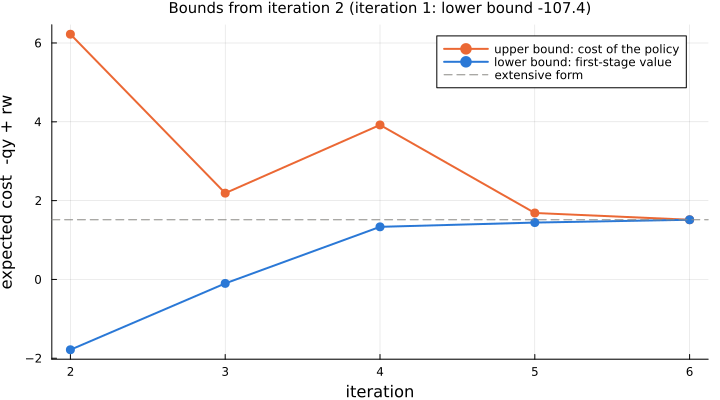

In [18]:
blue, orange, gray = "#2a78d6", "#eb6834", "#8a8984"
it = [h.iteration for h in result.history][2:end]
plot(it, [h.upper for h in result.history][2:end]; color = orange, lw = 2, marker = :circle,
     ms = 5, msw = 0, label = "upper bound: cost of the policy")
plot!(it, [h.lower for h in result.history][2:end]; color = blue, lw = 2, marker = :circle,
      ms = 5, msw = 0, label = "lower bound: first-stage value")
hline!([z_star]; color = gray, lw = 1, ls = :dash, label = "extensive form")
plot!(xlabel = "iteration", ylabel = "expected cost  -qy + rw", size = (720, 400),
      gridalpha = 0.15, framestyle = :axes, legend = :topright,
      title = "Bounds from iteration 2 (iteration 1: lower bound -107.4)", titlefontsize = 10)

## 9. The optimal policy

When the method stops, `result.x̂` holds the trial decisions of the last forward pass, and every node
model its solution: the other variables are read by name in the model of their node, as in any JuMP
model.

In [19]:
outcome(ω) = ω == [1.25, 1.14] ? "good" : "bad"
path_of(tree, k) = k == 1 ? String[] : [path_of(tree, tree.nodes[k].parent); outcome(tree.nodes[k].data)]
clean(x) = abs(x) < 1e-9 ? 0.0 : x          # no -0.000 in the tables

@printf("%4s %5s  %-18s %9s %9s\n", "node", "stage", "periods observed", "stocks", "bonds")
for k in eachindex(tree.nodes)
    tree.nodes[k].stage <= 3 || continue
    @printf("%4d %5d  %-18s %9.3f %9.3f\n", k, tree.nodes[k].stage, join(path_of(tree, k), ", "),
            clean.(result.x̂[k])...)
end
@printf("\n%4s  %-18s %9s %9s\n", "node", "periods observed", "surplus", "shortfall")
for k in stage_nodes(tree, 4)
    m = nb.nodes[k].model
    @printf("%4d  %-18s %9.3f %9.3f\n", k, join(path_of(tree, k), ", "), clean(value(m[:y])),
            clean(value(m[:w])))
end

node stage  periods observed      stocks     bonds
   1     1                        41.479    13.521


   2     2  good                  65.095     2.168
   3     2  bad                   36.743    22.368
   4     3  good, good            83.840     0.000
   5     3  good, bad              0.000    71.429
   6     3  bad, good              0.000    71.429
   7     3  bad, bad              64.000     0.000

node  periods observed     surplus shortfall
   8  good, good, good      24.800     0.000


   9  good, good, bad        8.870     0.000
  10  good, bad, good        1.429     0.000
  11  good, bad, bad         0.000     0.000
  12  bad, good, good        1.429     0.000
  13  bad, good, bad         0.000     0.000
  14  bad, bad, good         0.000     0.000
  15  bad, bad, bad          0.000    12.160


The policy reacts to what it observes, as Birge and Louveaux describe it:

- after two good periods (node 4), the wealth, 83.84, exceeds the goal even if stocks then do badly
  ($83.84 \cdot 1.06 = 88.9$): everything goes to stocks, whose expected return is higher;
- after one good and one bad period (nodes 5 and 6), the wealth, $71.43 = 80/1.12$, is exactly what
  bonds need to reach the goal: the policy secures it;
- after two bad periods (node 7), bonds would not suffice ($64 \cdot 1.12 = 71.7$), while stocks
  reach the goal exactly if the last period is good ($64 \cdot 1.25 = 80$): the policy bets on
  them, and the only shortfall is in the worst scenario.

## 10. Inside the root: cuts versus the expected cost-to-go

The first-stage decision lies on the budget line $x_1 = (s, b - s)$, $s \in [0, b]$, so that
$\mathcal{Q}_2(x_1)$ can be drawn as a function of $s$. We compute it exactly, by fixing $x_1$ in the
extensive form (the root has no cost), and compare it with the cuts the root has received.

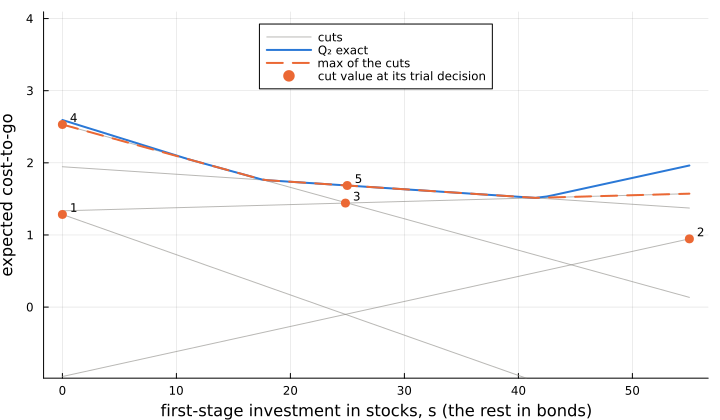

In [20]:
b = 55.0
ef2, xout2 = extensive_form(tree, build!; optimizer = HiGHS.Optimizer)
grid = range(0, b; length = 111)
Q2 = map(grid) do s
    fix.(xout2[1], [s, b - s]; force = true)
    optimize!(ef2)
    objective_value(ef2)
end

cuts = nb.nodes[1].optimality_cuts
on_line(c, s) = c.value + c.slope' * ([s, b - s] - c.point)
approximation = [max(θ_min, maximum(on_line(c, s) for c in cuts)) for s in grid]

p = plot(xlabel = "first-stage investment in stocks, s (the rest in bonds)",
         ylabel = "expected cost-to-go", size = (720, 420), gridalpha = 0.15,
         framestyle = :axes, legend = :top)
for (i, c) in enumerate(cuts)
    plot!(p, grid, on_line.(Ref(c), grid); color = gray, lw = 1, alpha = 0.6,
          label = i == 1 ? "cuts" : "")
end
plot!(p, grid, Q2; color = blue, lw = 2, label = "Q₂ exact")
plot!(p, grid, approximation; color = orange, lw = 2, ls = :dash, label = "max of the cuts")
scatter!(p, [c.point[1] for c in cuts], [c.value for c in cuts]; color = orange, ms = 5, msw = 0,
         label = "cut value at its trial decision")
for (i, c) in enumerate(cuts)
    annotate!(p, c.point[1], c.value, text("  $i", 8, :left, :bottom))
end
ylims!(p, minimum(Q2) - 2.5, maximum(Q2) + 1.5)
p

In [21]:
@printf("%4s %10s %12s %12s\n", "cut", "trial s", "cut value", "exact Q₂")
for (i, c) in enumerate(cuts)
    fix.(xout2[1], c.point; force = true)
    optimize!(ef2)
    @printf("%4d %10.3f %12.4f %12.4f\n", i, c.point[1], c.value, objective_value(ef2))
end
s_final = result.x̂[1][1]
fix.(xout2[1], result.x̂[1]; force = true)
optimize!(ef2)
@printf("\nFinal decision s = %.3f: max of the cuts %.4f, exact Q₂ %.4f\n", s_final,
        maximum(on_line(c, s_final) for c in cuts), objective_value(ef2))

 cut    trial s    cut value     exact Q₂
   1      0.000       1.2843       2.5940


   2     55.000       0.9459       1.9631
   3     24.830       1.4421       1.6874
   4      0.000       2.5316       2.5940
   5     24.984       1.6858       1.6858

Final decision s = 41.479: max of the cuts 1.5141, exact Q₂ 1.5141


The cuts lie below $\mathcal{Q}_2$, as they must, but the early ones do not touch it at their trial
decision: they were built when the nodes below the root only knew their own approximations, still
too optimistic. A cut touches $\mathcal{Q}_2$ at its trial decision only once the approximations
below are exact there, as cut 5 does.

The method stops when the approximation is exact at the first-stage decision itself: at
$s = 41.48$, where two cuts cross, the maximum of the cuts equals $\mathcal{Q}_2$, and the
first-stage value, the lower bound, is then the cost of the policy. Elsewhere, near $s = 55$ for
instance, the approximation stays below $\mathcal{Q}_2$: the method never needs the expected
cost-to-go everywhere, only around the decisions it ends up making.

## 11. Feasibility cuts: a borrowing limit

Let us cap the shortfall at 5: the final wealth must reach 75 in every scenario. This is possible,
since bonds alone give $55 \cdot 1.12^3 = 77.3$ in the worst case, but not for every policy: some
trial decisions leave leaves infeasible, and their parents receive feasibility cuts.

In [22]:
build_limited! = financial_builder(borrowing_limit = 5.0)
ef3, xout3 = extensive_form(tree, build_limited!; optimizer = HiGHS.Optimizer)
optimize!(ef3)
nb3 = NestedProblem(tree, build_limited!; optimizer = HiGHS.Optimizer, lower_bound = θ_min)
result3 = nested_benders!(nb3)
@printf("\n%s: value %.6f (extensive form %.6f)\n", result3.status, result3.upper, objective_value(ef3))
@printf("First stage: stocks %.3f, bonds %.3f (without the limit: %.3f, %.3f)\n",
        result3.x̂[1]..., result.x̂[1]...)

 iter    lower bound    upper bound         gap   opt.  feas.    LPs
    1    -107.421875            Inf         Inf      0      2     17


    2    -107.421875            Inf         Inf      0      4     26
    3    -107.421875       5.553492   1.130e+02      0      4     41
    4      -4.019616            Inf         Inf      7      5     52
    5      -2.093849       4.918681   7.013e+00      7      5     67
    6       2.111326       3.528529   1.417e+00     14      5     89
    7       2.439218       2.618605   1.794e-01     21      5    111
    8       2.451671       2.451671  -3.981e-12     28      5    133

optimal: value 2.451671 (extensive form 2.451671)
First stage: stocks 8.687, bonds 46.313 (without the limit: 41.479, 13.521)


In [23]:
for (k, node) in enumerate(nb3.nodes), c in node.feasibility_cuts
    @printf("node %2d (stage %d): %.4f + (%.4f, %.4f)'(x - (%.3f, %.3f)) <= 0\n",
            k, tree.nodes[k].stage, c.value, c.slope..., c.point...)
end

node  1 (stage 1): 1.3299 + (-0.9464, -1.0000)'(x - (55.000, 0.000)) <= 0
node  2 (stage 2): 0.4485 + (-0.9464, -1.0000)'(x - (62.700, 0.000)) <= 0


node  3 (stage 2): 1.4895 + (-0.9464, -1.0000)'(x - (61.600, 0.000)) <= 0
node  5 (stage 3): 4.0627 + (-0.9464, -1.0000)'(x - (66.462, 0.000)) <= 0
node  7 (stage 3): 5.1663 + (-0.9464, -1.0000)'(x - (65.296, 0.000)) <= 0


The feasibility cuts appear in the first iterations, when the trial decisions are still arbitrary;
they are received by the nodes of stage 3, whose children are the leaves, and also higher up, when a
node becomes infeasible because of the feasibility cuts of its own children. Once the cuts are in
place, the forward passes are feasible, and the optimality cuts take over. The limit costs some
expected utility, and moves the first-stage decision toward bonds.

## 12. Dependent returns: any tree will do

Nothing in the method assumes stagewise independence. Suppose that a good period is followed by a
good one with probability 0.7, and a bad one by a good one with probability 0.3: the tree is the same,
with other branch probabilities, and every node keeps its own expected cost-to-go. (SDDP, which shares
the cuts of a stage, would need its Markovian extension.)

In [24]:
good, bad = [1.25, 1.14], [1.06, 1.12]
markov = ScenarioTree()
function grow!(tree, k, t, H)
    t > H && return
    pgood = tree.nodes[k].data === nothing ? 0.5 : (tree.nodes[k].data == good ? 0.7 : 0.3)
    grow!(tree, add_node!(tree, k, pgood, good), t + 1, H)
    grow!(tree, add_node!(tree, k, 1 - pgood, bad), t + 1, H)
end
grow!(markov, 1, 1, 3)

ef4, _ = extensive_form(markov, build!; optimizer = HiGHS.Optimizer)
optimize!(ef4)
nb4 = NestedProblem(markov, build!; optimizer = HiGHS.Optimizer, lower_bound = θ_min)
result4 = nested_benders!(nb4)
@printf("\n%s: value %.6f (extensive form %.6f)\n", result4.status, result4.upper, objective_value(ef4))
@printf("First stage: stocks %.3f, bonds %.3f\n", result4.x̂[1]...)

 iter    lower bound    upper bound         gap   opt.  feas.    LPs
    1    -107.421875       7.768414   1.152e+02      0      0     15


    2      -1.280286       2.271508   3.552e+00      7      0     37
    3      -0.135068       1.735005   1.870e+00     14      0     59
    4       1.474638       1.608918   1.343e-01     21      0     81
    5       1.536191       1.536191   1.001e-12     28      0    103

optimal: value 1.536191 (extensive form 1.536191)
First stage: stocks 31.848, bonds 23.152


## 13. What it costs

Every iteration solves every node of the tree, and the tree grows exponentially with the number of
stages. To keep the problem nontrivial as the horizon grows, the goal grows at the rate of the
original example, $G = 55\,(80/55)^{H/3}$.

In [25]:
@printf("%3s %6s %6s %8s %13s %13s %9s %9s\n", "H", "nodes", "iter.", "LPs", "nested",
        "extensive", "time NB", "time EF")
for H in 3:8
    tree_H = financial_tree(H)
    build_H! = financial_builder(H = H, G = 55 * (80 / 55)^(H / 3))
    t_ef = @elapsed begin
        m, _ = extensive_form(tree_H, build_H!; optimizer = HiGHS.Optimizer)
        optimize!(m)
    end
    t_nb = @elapsed begin
        nb_H = NestedProblem(tree_H, build_H!; optimizer = HiGHS.Optimizer,
                             lower_bound = -55 * 1.25^H)
        r_H = nested_benders!(nb_H; verbose = false)
    end
    @printf("%3d %6d %6d %8d %13.6f %13.6f %8.2fs %8.2fs\n", H, length(tree_H.nodes),
            length(r_H.history), r_H.history[end].solves, r_H.upper, objective_value(m), t_nb, t_ef)
end

  H  nodes  iter.      LPs        nested     extensive   time NB   time EF
  3     15      6      125      1.514085      1.514085     0.02s     0.00s


  4     31     13      583      1.026207      1.026207     0.06s     0.00s
  5     63      7      627     -0.416246     -0.416246     0.08s     0.00s


  6    127      7     1267     -2.575460     -2.575460     0.18s     0.00s
  7    255     10     3693     -5.283765     -5.283765     0.51s     0.01s


  8    511     11     8171     -9.247696     -9.247696     1.11s     0.02s


The number of linear programs grows with the size of the tree, and the extensive form is much faster
here: its linear program is tiny, and solving it at once beats hundreds of small solves through JuMP.
Decomposition pays off when the problem of a node is large, or the tree too big for the extensive form
to fit in memory; and when the tree itself is too big to be enumerated, the forward pass must sample
it, which is what SDDP does under stagewise independence (slides *07. SDDP*).

## To go further

- **Multicut**: give node $j$ one variable $\theta_{t,k}$ per child instead of one for their average,
  as in the multicut L-shaped method, and compare the number of iterations.
- **Sequencing**: the passes here go all the way down and all the way up. Birge and Louveaux discuss
  other protocols (fast-forward, fast-back): change direction as soon as a node gets a new cut.
- **Cut sharing**: under stagewise independence, the nodes of a stage have the same expected
  cost-to-go; make them share one set of cuts, and compare with *SDDP_from_scratch*.
- **Another model**: write a builder for the production planning problem of the slides.